# Figuras del informe

Este notebook regenera **todas las figuras del informe** a partir de los datos ya calculados
(`run/data/` y `analysis/output/`). No corre simulaciones ni modifica los scripts de análisis:
solo lee CSV y grafica, así que se puede tocar libremente el estilo de cada figura.

- Cada figura se guarda en esta carpeta (`figuras/`) en `.pdf` y `.png`, con el **mismo nombre**
  que usa `informe/main.tex`.
- Para que LaTeX las tome, `figuras/` tiene que ir **primero** en el `\graphicspath`:
  ```latex
  \graphicspath{{../figuras/}{../analysis/output/}{../run/data/}}
  ```
  LaTeX busca en orden, así que estas versiones tapan a las de los scripts. Si en `main.tex`
  se saca la extensión (`\includegraphics{binder_crossing}`), pdfLaTeX elige el `.pdf` (vectorial).
- Ejecutar desde esta carpeta (Jupyter / VS Code lo hacen por defecto) y con el entorno del proyecto.

In [1]:
using Pkg
Pkg.activate("..")   # Project.toml de la raiz del repositorio

  Activating project at `d:\Gits\cursos-posgrado-famaf\2025\fenomenos-criticos\ising-fenomenos-criticos`


## Configuración general

In [2]:
using Plots, Measures, LaTeXStrings, ColorSchemes
using CSV, DataFrames, Statistics, Polynomials, Printf
gr()

const ROOT = normpath(joinpath(pwd(), ".."))
const DATA = joinpath(ROOT, "run", "data")         # datos de simulacion
const ANA  = joinpath(ROOT, "analysis", "output")  # resultados de los scripts de analisis
const OUT  = joinpath(ROOT, "figuras")             # destino de las figuras
mkpath(OUT)

# Estilo comun a todas las figuras (cambiar aca para tocar todo junto)
default(
    fontfamily = "Computer Modern",
    framestyle = :box,
    # grid = false,
    titlelocation = :left,
    titlefontsize = 12, guidefontsize = 13, tickfontsize = 10, legendfontsize = 10,
    foreground_color_legend = nothing, background_color_legend = nothing,
    lw = 1.5, markerstrokewidth = 0,
    minorticks=true,
    margin = 3mm,
    dpi = 300,
)
const ANCHO = 680   # ancho de referencia (px) de una figura a \textwidth

const Tc_ex = 2 / log(1 + sqrt(2))   # Onsager
const Ls = [16, 32, 64, 128, 200]
const colL = Dict(zip(Ls, get(ColorSchemes.viridis, range(0.0, 0.85, length = length(Ls)))))
labL(L) = latexstring("L = $L")

"Guarda la figura en OUT como .pdf y .png y la devuelve (para verla en el notebook)."
function guardar(p, nombre)
    savefig(p, joinpath(OUT, nombre * ".pdf"))
    savefig(p, joinpath(OUT, nombre * ".png"))
    return p
end

leer(dir, archivo) = CSV.read(joinpath(dir, archivo), DataFrame)

leer (generic function with 1 method)

## Datos y resultados de los análisis

In [3]:
eq     = Dict(L => sort!(leer(DATA, "equilibrium_observables_L$L.csv"), :T) for L in Ls)
picos  = sort!(leer(ANA, "fss_peaks_summary.csv"), :L)      # T*, chi_max, FWHM, Cv_max
tcobs  = sort!(leer(ANA, "observables_at_Tc.csv"), :L)      # <|m|>, |dU/dT|, chi en Tc (Binder)
infl   = sort!(leer(ANA, "inflection_points.csv"), :L)
alta   = leer(ANA, "high_T_magnetization.csv")
cruces = leer(ANA, "binder_crossings.csv")
binder = leer(ANA, "binder_tc_estimate.csv")
expo   = leer(ANA, "exponents_summary.csv")

const Tc_B     = binder.Tc[1]
const Tc_B_err = hypot(binder.Tc_err_stat[1], binder.Tc_err_sist[1])
@assert picos.L == Ls && tcobs.L == Ls && infl.L == Ls
@printf("Tc (Binder) = %.5f +/- %.5f\n", Tc_B, Tc_B_err)

Tc (Binder) = 2.26928 +/- 0.00038


## Funciones auxiliares

Copias de las de `analysis/*.jl` (mismos criterios), para no depender de los scripts.

In [5]:
"Regresion lineal ponderada (incertezas infladas por sqrt(chi2_red) si > 1); sin pesos, del residuo."
function linear_fit(x, y; sigma = nothing)
    n = length(x)
    s = sigma === nothing ? ones(n) : sigma
    w = 1 ./ s .^ 2
    S, Sx, Sy = sum(w), sum(w .* x), sum(w .* y)
    Sxx, Sxy = sum(w .* x .^ 2), sum(w .* x .* y)
    Δ = S * Sxx - Sx^2
    slope = (S * Sxy - Sx * Sy) / Δ
    intercept = (Sxx * Sy - Sx * Sxy) / Δ
    chi2 = sum(w .* (y .- intercept .- slope .* x) .^ 2) / max(1, n - 2)
    sc = sigma === nothing ? sqrt(chi2) : max(1.0, sqrt(chi2))
    return (slope = slope, intercept = intercept,
            slope_err = sqrt(S / Δ) * sc, intercept_err = sqrt(Sxx / Δ) * sc, chi2_red = chi2)
end

"Ley de potencia y = A L^k en log-log (errores relativos si se dan)."
power_fit(L, y; sigma = nothing) =
    linear_fit(log.(L), log.(y); sigma = sigma === nothing ? nothing : sigma ./ y)

"Polinomio local en x = T - T0 dentro de |T - T0| <= hw (ponderado si se da sigma)."
function local_poly(T, Y, T0, hw, deg; sigma = nothing)
    m = abs.(T .- T0) .<= hw
    x = T[m] .- T0
    y = Y[m]
    s = sigma === nothing ? ones(length(x)) : sigma[m]
    A = hcat([x .^ k for k in 0:deg]...) ./ s
    return (p = Polynomial(A \ (y ./ s)), T0 = T0, x = x)
end

# --- Solucion exacta (J = k_B = 1, por espin) -------------------------------
"Integrales elipticas completas K(k), E(k) por media aritmetico-geometrica."
function elliptic_KE(k)
    a, b, c = 1.0, sqrt(1 - k^2), k
    suma, pot = 0.5 * c^2, 0.5
    while abs(c) > 1e-15
        a, b, c = (a + b) / 2, sqrt(a * b), (a - b) / 2
        pot *= 2
        suma += pot * c^2
    end
    K = π / (2 * a)
    return K, K * (1 - suma)
end
mag_exact(T) = T < Tc_ex ? (1 - sinh(2 / T)^(-4))^(1 / 8) : 0.0          # Yang (1952)
function onsager_u_c(T)                                                   # Onsager (1944)
    K = 1 / T
    κ = 2 * sinh(2K) / cosh(2K)^2
    κp = 2 * tanh(2K)^2 - 1
    K1, E1 = elliptic_KE(κ)
    u = -coth(2K) * (1 + (2 / π) * κp * K1)
    c = (2 / π) * (K * coth(2K))^2 * (2 * K1 - 2 * E1 - (1 - κp) * (π / 2 + κp * K1))
    return u, c
end
ene_exact(T) = onsager_u_c(T)[1]
cv_exact(T)  = onsager_u_c(T)[2]

Tf   = filter(T -> abs(T - Tc_ex) > 1e-6, collect(range(1.0, 4.0, length = 3001)))
m_ex = mag_exact.(Tf)
e_ex = ene_exact.(Tf)
c_ex = cv_exact.(Tf)

3001-element Vector{Float64}:
 0.023379564686542193
 0.02352840836899432
 0.023677888304274315
 0.02382800563261151
 0.02397876149173174
 0.02413015701686417
 0.024282193340749908
 0.024434871593640675
 0.024588192903312243
 0.02474215839506567
 ⋮
 0.17210056235920726
 0.1719861214916001
 0.17187180155362142
 0.17175760236676596
 0.1716435237528725
 0.17152956553411947
 0.17141572753302964
 0.17130200957246508
 0.17118841147563013

## Sección 2.3 — Autocorrelación (`decorrelation_L64_nT96`)

$\rho_{|m|}(t)$ para todas las $T$ del estudio (color de frío a caliente; en negro, la del máximo de $\tau$)
y $\tau_\mathrm{int}(T)$ de $|m|$ y $e$. Para otro tamaño, cambiar `L` (16, 32, 64, 128, 200).

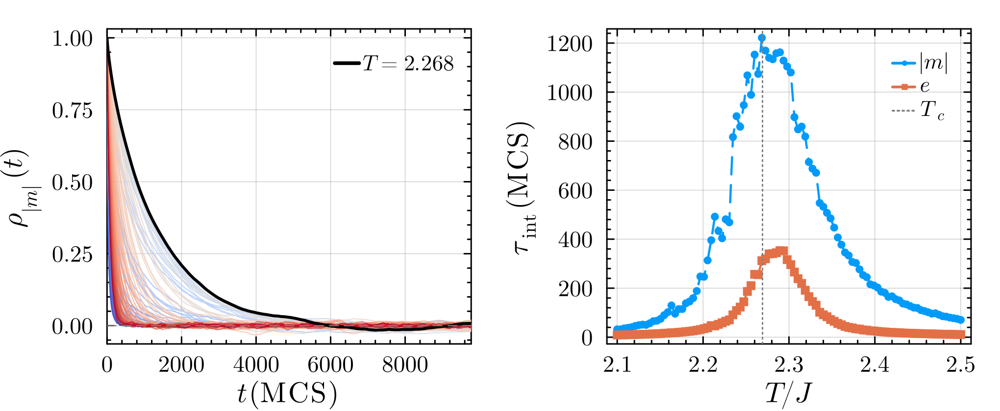

In [12]:
let L = 64
    dec = leer(DATA, "decorrelation_L$(L)_nT96.csv")
    rho = leer(DATA, "autocorrelation_curves_L$(L)_nT96.csv")   # columnas: lag, T_2.100, ...
    cols_T = names(rho)[2:end]
    @assert length(cols_T) == nrow(dec)
    @assert all(abs(parse(Float64, c[3:end]) - T) < 1e-3 for (c, T) in zip(cols_T, dec.T))

    Tmin, Tmax = extrema(dec.T)
    ipk = argmax(dec.tau_int_mag)
    grad = cgrad(:coolwarm)

    p1 = plot(xlabel = L"t \, \mathrm{(MCS)}", ylabel = L"\rho_{|m|}(t)", legend = :topright,
              xlims = (0, 8 * dec.tau_int_mag[ipk]))
    for (i, c) in enumerate(cols_T)
        i == ipk && continue
        plot!(p1, rho.lag, rho[!, c], color = grad[(dec.T[i] - Tmin) / (Tmax - Tmin)], lw = 0.7, alpha = 0.8, label = "")
    end
    plot!(p1, rho.lag, rho[!, cols_T[ipk]], color = :black, lw = 2,
          label = latexstring(@sprintf("T = %.3f", dec.T[ipk])))
    hline!(p1, [0.0], color = :gray, ls = :dash, lw = 0.8, label = "")

    p2 = plot(xlabel = L"T/J", ylabel = L"\tau_\mathrm{int} \, \mathrm{(MCS)}", legend = :topright)
    plot!(p2, dec.T, dec.tau_int_mag, marker = :circle, ms = 3, label = L"|m|",ls=:dash)
    plot!(p2, dec.T, dec.tau_int_ene, marker = :square, ms = 3, label = L"e",ls=:dash)
    vline!(p2, [Tc_ex], color = :gray, ls = :dot, lw = 1, label = L"T_c")

    fig = plot(p1, p2, layout = (1, 2), size = (ANCHO, 280))
    guardar(fig, "decorrelation_L$(L)_nT96")
end

## Ítem (a) — Observables frente a la solución exacta (`observables_vs_exact`, `observables_near_Tc`)

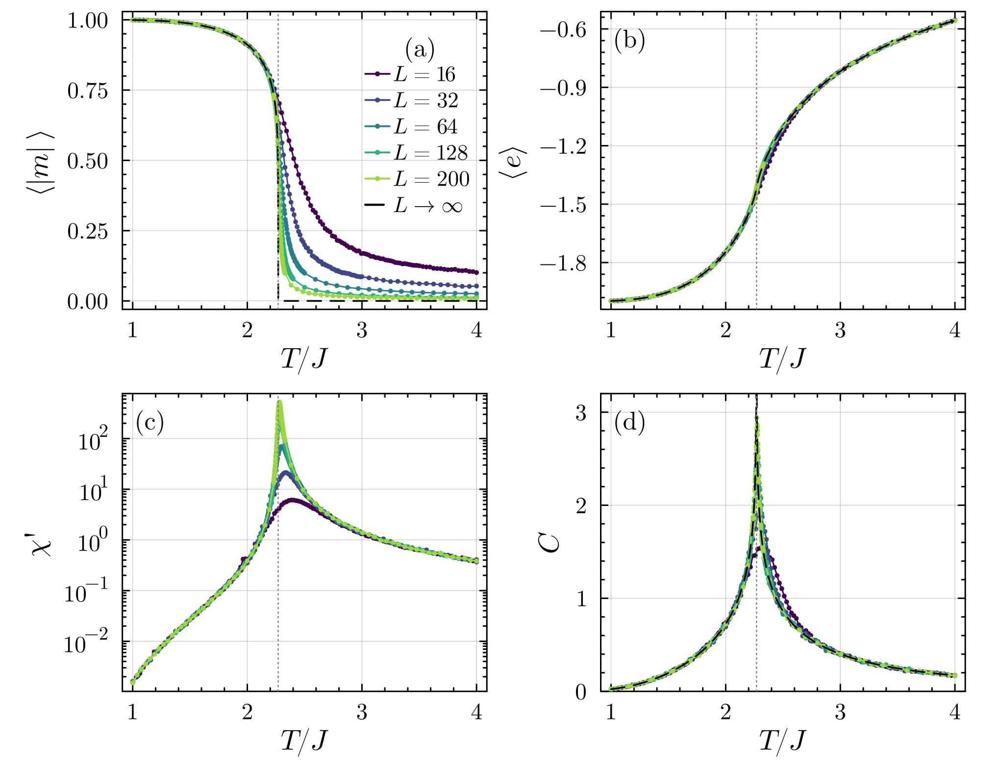

In [33]:
"""
Escribe la letra del panel `s` dentro de los ejes, en la posicion relativa `pos`
((0, 0) = abajo a la izquierda, (1, 1) = arriba a la derecha). Funciona con ejes
lineales o logaritmicos. Fija los limites actuales para que la anotacion no los cambie.
"""
function letra!(p, s; pos = (0.04, 0.95), fs = 11)
    sp = p[1]
    (x0, x1), (y0, y1) = xlims(sp), ylims(sp)
    interp(a, b, t, esc) = esc == :log10 ? 10^(log10(a) + t * (log10(b) - log10(a))) : a + t * (b - a)
    x = interp(x0, x1, pos[1], sp[:xaxis][:scale])
    y = interp(y0, y1, pos[2], sp[:yaxis][:scale])
    plot!(p, xlims = (x0, x1), ylims = (y0, y1))
    annotate!(p, x, y, text(s, fs, "Computer Modern", pos[1] > 0.5 ? :right : :left, :top))
    return p
end

"""
Panel de un observable para todos los L.
- `letra`    : rotulo del panel ("(a)", "(b)", ...). Si el panel tiene leyenda, va como su
               titulo (`legend_title`); si no, se escribe dentro de los ejes en `pos_letra`.
- `leyenda`  : posicion de la leyenda (`false` = sin leyenda). Ponerla solo en un panel.
- `pos_letra`: posicion relativa de la letra cuando no hay leyenda (ver `letra!`).
- `kw...`    : cualquier otro atributo de Plots (xlims, yscale, ...).
"""
function panel_obs(col, ylab; exacto = nothing, leyenda = false, letra = "", pos_letra = (0.04, 0.95), kw...)
    titulo_ley = leyenda === false ? nothing : letra
    p = plot(; xlabel = L"T/J", ylabel = ylab, legend = leyenda, legend_title = titulo_ley, kw...)
    for L in Ls
        d = eq[L]
        plot!(p, d.T, d[!, col], color = colL[L], lw = 1, marker = :circle, ms = 1.8, label = labL(L))
    end
    exacto === nothing || plot!(p, Tf, exacto, color = :black, ls = :dash, lw = 1.2, label = L"L \to \infty")
    vline!(p, [Tc_ex], color = :gray, ls = :dot, lw = 0.8, label = "")
    (leyenda === false && !isempty(letra)) && letra!(p, letra; pos = pos_letra)
    return p
end

let
    # Leyenda (colores de L y exacto) solo en (a), con su letra como titulo;
    # en (b)-(d) la letra va dentro de los ejes, arriba a la izquierda
    p_m  = panel_obs(:mag_abs, L"\langle |m| \rangle"; exacto = m_ex, letra = "(a)", leyenda = :topright)
    p_e  = panel_obs(:ene_per_spin, L"\langle e \rangle"; exacto = e_ex, letra = "(b)")
    p_χ  = panel_obs(:susceptibilidad, L"\chi'"; yscale = :log10, letra = "(c)")
    p_cv = panel_obs(:calor_especifico, L"C"; exacto = c_ex, ylims = (0, 3.2), letra = "(d)")
    fig = plot(p_m, p_e, p_χ, p_cv, layout = (2, 2), size = (ANCHO, 520),
    left_margin=[4mm 0mm],
    right_margin = [0mm 4mm],
    bottom_margin = [0mm 0mm],
    top_margin = [0mm 0mm]
    )
    guardar(fig, "observables_vs_exact")
end

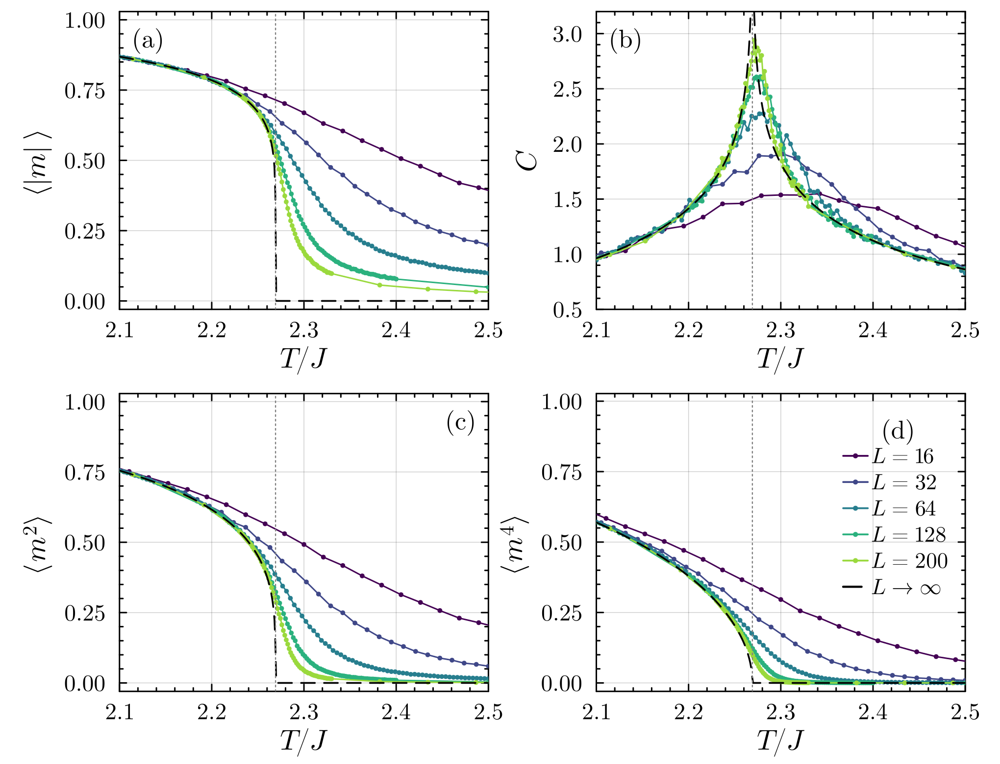

In [38]:
let xz = (2.1, 2.5)
    # En el zoom, <|m|>, <m^2> y <m^4> ocupan la esquina superior izquierda: letra arriba a la derecha
    p_m  = panel_obs(:mag_abs, L"\langle |m| \rangle"; exacto = m_ex, xlims = xz, letra = "(a)", leyenda = false)
    p_cv = panel_obs(:calor_especifico, L"C"; exacto = c_ex, xlims = xz, ylims = (0.5, 3.2), letra = "(b)")
    p_m2 = panel_obs(:m2, L"\langle m^2 \rangle"; exacto = m_ex .^ 2, xlims = xz, letra = "(c)", pos_letra = (0.96, 0.95))
    p_m4 = panel_obs(:m4, L"\langle m^4 \rangle"; exacto = m_ex .^ 4, xlims = xz, letra = "(d)", pos_letra = (0.96, 0.95), leyenda=:topright)
    fig = plot(p_m, p_cv, p_m2, p_m4, layout = (2, 2), size = (ANCHO, 520),
    left_margin=[4mm 0mm],
    right_margin = [0mm 4mm],
    bottom_margin = [0mm 0mm],
    top_margin = [0mm 0mm]
    )
    guardar(fig, "observables_near_Tc")
end

## Ítem (b) — Punto de inflexión de $\langle|m|\rangle$ (`magnetization_inflection`)

Pendiente $-d\langle|m|\rangle/dT$ de los ajustes locales (grado 3, ventana $\pm 2/L$, como en
`scaling_exponents.jl`), extrapolación en $1/L$ y saturación $\propto N^{-1/2}$ a alta $T$.

Tc (inflexion, 1/L -> 0) = 2.2712 +/- 0.0014  [reportado 2.2712 +/- 0.0014 estad.]


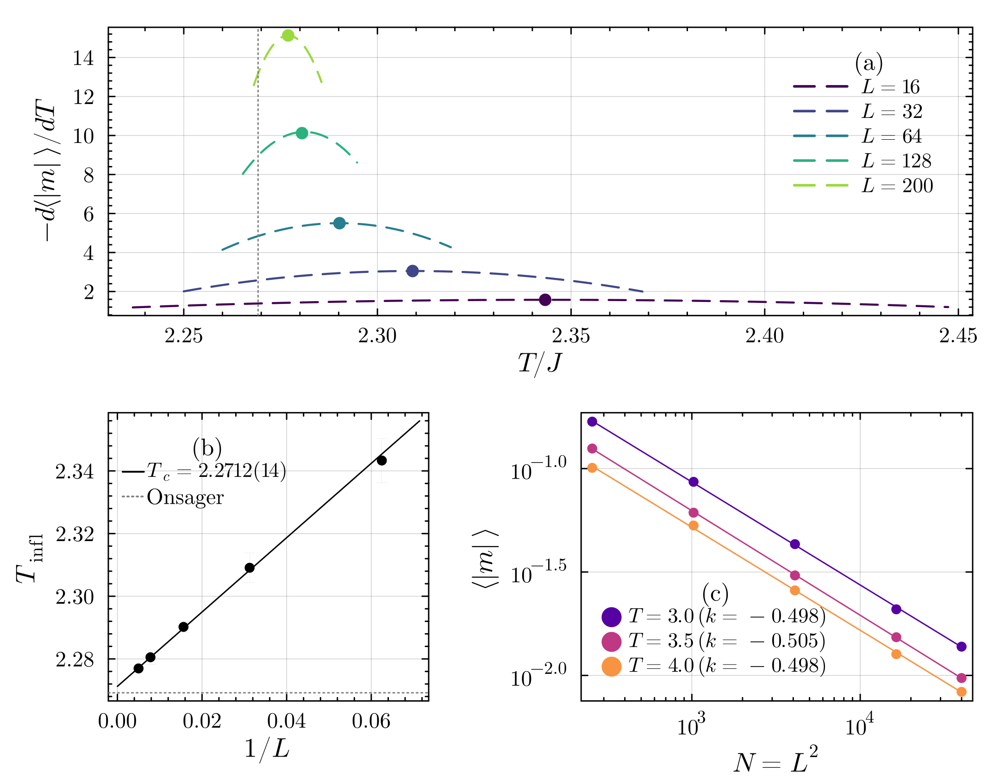

In [15]:
let
    p1 = plot(xlabel = L"T/J", ylabel = L"-d\langle |m| \rangle / dT", legend = :topright,legend_title="(a)")
    for (i, L) in enumerate(Ls)
        d = eq[L]
        aj = local_poly(Float64.(d.T), Float64.(d.mag_abs), infl.T_infl[i], 2.0 / L, 3;
                        sigma = Float64.(d.mag_err))
        xf = range(extrema(aj.x)..., length = 200)
        plot!(p1, aj.T0 .+ xf, -derivative(aj.p).(xf), color = colL[L], label = labL(L),ls=:dash)
        scatter!(p1, [infl.T_infl[i]], [infl.slope_infl[i]], color = colL[L], ms = 5, label = "")
    end
    vline!(p1, [Tc_ex], color = :gray, ls = :dot, lw = 1, label = "")

    f = linear_fit(1 ./ Ls, infl.T_infl; sigma = infl.T_infl_err)
    xe = range(0, 1 / 14, length = 50)
    p2 = scatter(1 ./ Ls, infl.T_infl, yerror = infl.T_infl_err, color = :black, ms = 4, label = "",
                 xlabel = L"1/L", ylabel = L"T_\mathrm{infl}", legend = :topleft, legend_title="(b)")
    plot!(p2, xe, f.intercept .+ f.slope .* xe, color = :black, lw = 1,
          label = latexstring(@sprintf("T_c = %.4f(%d)", f.intercept, round(Int, 1e4 * f.intercept_err))))
    hline!(p2, [Tc_ex], color = :gray, ls = :dot, lw = 1, label = "Onsager")
    @printf("Tc (inflexion, 1/L -> 0) = %.4f +/- %.4f  [reportado 2.2712 +/- 0.0014 estad.]\n",
            f.intercept, f.intercept_err)

    p3 = plot(xlabel = L"N = L^2", ylabel = L"\langle |m| \rangle", xscale = :log10, yscale = :log10,
              legend = :bottomleft, legend_title="(c)")
    for (k, Ta) in enumerate([3.0, 3.5, 4.0])
        sub = sort!(alta[alta.T .== Ta, :], :N)
        g = power_fit(Float64.(sub.N), sub.mag_abs; sigma = sub.mag_err)
        c = get(ColorSchemes.plasma, 0.15 + 0.3 * (k - 1))
        scatter!(p3, sub.N, sub.mag_abs, yerror = sub.mag_err, color = c, ms = 4,
                 label = latexstring(@sprintf("T = %.1f \\; (k = %.3f)", Ta, g.slope)))
        plot!(p3, sub.N, exp(g.intercept) .* Float64.(sub.N) .^ g.slope, color = c, lw = 1, label = "")
    end

    fig = plot(p1, p2, p3, layout = @layout([a; b c{0.55w}]), size = (720, 560),bottom_margin = 0Plots.mm)
    guardar(fig, "magnetization_inflection")
end

## Ítem (c) — Cruce del cumulante de Binder (`binder_crossing`)

Convención del código: $U_L = 1 - \langle m^4\rangle / (3\langle m^2\rangle^2)$. Para la de la guía,
$\langle m^4\rangle/\langle m^2\rangle^2 = 3(1 - U_L)$: cambiar la función `U` de abajo.
Ajustes locales de grado 3 en $|T - 2.27| \le 2/L$, como en `binder_crossing.jl`.

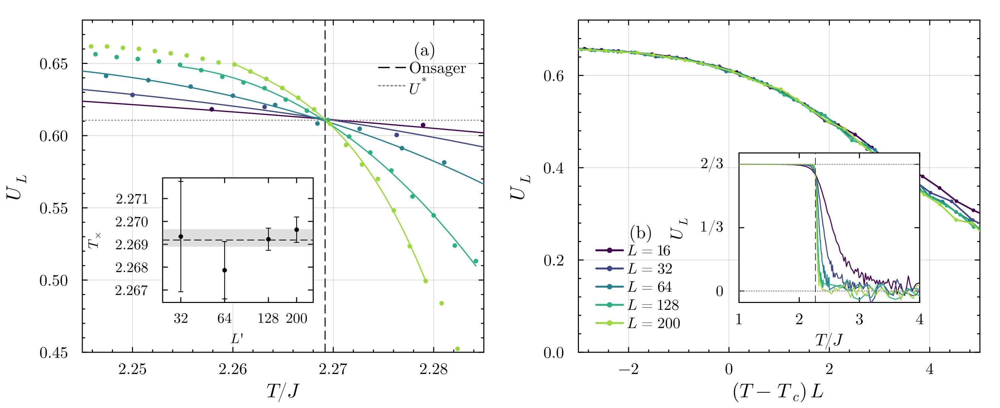

In [67]:
let
    # Convencion del cumulante. Codigo (Binder): U = 1 - <m^4>/(3<m^2>^2)  ->  limites 2/3 (T -> 0) y 0 (T -> inf)
    # Guia: U = <m^4>/<m^2>^2 = 3(1 - U_Binder)                        ->  limites 1 y 3 (cambiar tambien ylims)
    conv(u) = u                                  # guia: conv(u) = 3 * (1 - u)
    U(d) = conv.(Float64.(d.binder_cumulant))
    U_star = conv(0.61069)                       # Kamieniarz & Blote (1993)
    U_baja, U_alta = conv(2 / 3), conv(0.0)      # limites T -> 0 y T -> infinito

    # ---------------- (a) Cruce de U_L(T) cerca de Tc --------------------------------
    p1 = plot(xlabel = L"T/J", ylabel = L"U_L", xlims = (2.245, 2.285), ylims = (0.45, 0.68),
              legend = :topright, legend_title = "(a)")
    for L in Ls
        d = eq[L]
        T, u = Float64.(d.T), U(d)
        m = abs.(T .- 2.27) .<= 2.0 / L
        pol = Polynomials.fit(T[m], u[m], 3)
        scatter!(p1, T, u, color = colL[L], ms = 2.5, label = "")
        Tfino = range(extrema(T[m])..., length = 200)
        plot!(p1, Tfino, pol.(Tfino), color = colL[L], lw = 1.2, label = "")
    end
    vline!(p1, [Tc_ex], color = :black, ls = :dash, lw = 1, label = "Onsager")
    hline!(p1, [U_star], color = :gray, ls = :dot, lw = 1, label = L"U^*")

    # ---------------- (b) Colapso U_L vs (T - Tc) L ----------------------------------
    p2 = plot(xlabel = L"(T - T_c)\, L", ylabel = L"U_L", xlims = (-3, 5), ylims = (0, 0.72),
              legend = :bottomleft, legend_title = "(b)")
    for L in Ls
        d = eq[L]
        plot!(p2, (d.T .- Tc_B) .* L, U(d), color = colL[L], marker = :circle, ms = 2, label = labL(L))
    end

    fig = plot(p1, p2, layout = (1, 2), size = (980, 400),
               left_margin = 5mm, bottom_margin = 5mm)

    # Estilo comun de los insets
    kw_in = (tickfontsize = 6, guidefontsize = 7, legend = false, grid = false,
             background_color_subplot = :white, minorticks = false)

    # ---------------- inset de (a): T del cruce de pares consecutivos -> subplot 3 ----
    # (abajo a la izquierda: a T < Tc y U chico no hay datos)
    consec = filter(r -> findfirst(==(r.L1), Ls) + 1 == findfirst(==(r.L2), Ls), cruces)
    xr = (24.0, 260.0)
    plot!(fig, collect(xr), [Tc_B, Tc_B]; ribbon = Tc_B_err, fillalpha = 0.25, color = :gray, lw = 0,
          inset = (1, Plots.bbox(0.2, 0.15, 0.375, 0.375, :bottom, :left)), subplot = 3,
          xscale = :log2, xlims = xr, xticks = (consec.L2, string.(consec.L2)),
          xlabel = L"L'", ylabel = L"T_\times", yformatter = y -> @sprintf("%.3f", y), kw_in...,tickfontsize = 9, guidefontsize = 9)
    plot!(fig, collect(xr), [Tc_ex, Tc_ex]; subplot = 3, color = :black, ls = :dash, lw = 0.8)
    scatter!(fig, consec.L2, consec.T_cross; yerror = consec.T_cross_err, subplot = 3,
             color = :black, ms = 2.5, msw = 0.8, markerstrokecolor = :black)

    # ---------------- inset de (b): U_L(T) completo, con sus dos limites -> subplot 4 --
    # (abajo, a la derecha de la leyenda: el colapso no baja de U ~ 0.3 en este rango)
    for (k, L) in enumerate(Ls)
        d = eq[L]
        extra = k == 1 ? (inset = (2, Plots.bbox(0.15, 0.15, 0.45, 0.45, :bottom, :right)),
                          xlabel = L"T/J", ylabel = L"U_L", xlims = (1, 4),
                          ylims = extrema([U_baja, U_alta]) .+ (-0.06, 0.06),
                          yticks = (sort([U_alta, 1/3, U_baja]), [L"0",L"1/3", L"2/3"]),   # guia: [L"1", L"3"]
                          tickfontsize = 9, guidefontsize = 9, legend = false, grid = false,
                          kw_in...) : NamedTuple()
        plot!(fig, d.T, U(d); subplot = 4, color = colL[L], lw = 1, extra..., tickfontsize = 10, guidefontsize = 11, label = "")
    end
    hline!(fig, [U_baja, U_alta]; subplot = 4, color = :gray, ls = :dot, lw = 0.8, label = "")
    vline!(fig, [Tc_ex]; subplot = 4, color = :black, ls = :dash, lw = 0.6, label = "")

    guardar(fig, "binder_crossing",)
end

## Ítem (d) — Picos de $\chi'$: $T^*(L)$ y $\gamma/\nu$ (`fss_scaling_fits`)

In [ ]:
let
    Lf = Float64.(picos.L)
    tk = (Ls, string.(Ls))
    Lfino = range(14, 230, length = 100)

    fχ = power_fit(Lf, Float64.(picos.chi_max))
    p1 = scatter(Lf, picos.chi_max, xscale = :log10, yscale = :log10, xticks = tk, color = :black, ms = 4,
                 label = "", xlabel = L"L", ylabel = L"\chi'_\mathrm{max}", legend = :topleft)
    plot!(p1, Lfino, exp(fχ.intercept) .* Lfino .^ fχ.slope, color = :black, lw = 1,
          label = latexstring(@sprintf("\\gamma/\\nu = %.3f(%d)", fχ.slope, round(Int, 1e3 * fχ.slope_err))))

    fw = power_fit(Lf, Float64.(picos.FWHM_chi))
    p2 = scatter(Lf, picos.FWHM_chi, xscale = :log10, yscale = :log10, xticks = tk, color = :black, ms = 4,
                 label = "", xlabel = L"L", ylabel = L"\mathrm{FWHM}(\chi')", legend = :topright)
    plot!(p2, Lfino, exp(fw.intercept) .* Lfino .^ fw.slope, color = :black, lw = 1,
          label = latexstring(@sprintf("1/\\nu = %.3f(%d)", -fw.slope, round(Int, 1e3 * fw.slope_err))))

    ft = linear_fit(1 ./ Lf, Float64.(picos.T_star_chi))
    xe = range(0, 1 / 14, length = 50)
    p3 = scatter(1 ./ Lf, picos.T_star_chi, color = :black, ms = 4, label = "",
                 xlabel = L"1/L", ylabel = L"T^*(L)", legend = :topleft)
    plot!(p3, xe, ft.intercept .+ ft.slope .* xe, color = :black, lw = 1,
          label = latexstring(@sprintf("T_c = %.4f(%d)", ft.intercept, round(Int, 1e4 * ft.intercept_err))))
    hline!(p3, [Tc_ex], color = :gray, ls = :dot, lw = 1, label = "Onsager")

    # Letras dentro de los ejes, en la esquina libre de cada panel (las leyendas tienen una sola
    # entrada, asi que como legend_title quedan centradas y flotando). letra! esta en la celda del item (a).
    letra!(p1, "(a)"; pos = (0.96, 0.15))   # abajo a la derecha
    letra!(p2, "(b)"; pos = (0.04, 0.15))   # abajo a la izquierda
    letra!(p3, "(c)"; pos = (0.96, 0.15))   # abajo a la derecha, por encima de la linea de Onsager

    fig = plot(p1, p2, p3, layout = (1, 3), size = (800, 280), bottom_margin=5mm)
    @printf("gamma/nu = %.4f +/- %.4f [1.7557(65)] | 1/nu (FWHM) = %.3f | Tc(T*) = %.4f +/- %.4f [2.2701(11)]\n",
            fχ.slope, fχ.slope_err, -fw.slope, ft.intercept, ft.intercept_err)
    guardar(fig, "fss_scaling_fits")
end

## Ítem (e) — Exponentes por escalamiento de tamaño finito en $T_c$ (`critical_exponents_fss`)

Observables evaluados en el $T_c$ de Binder (`observables_at_Tc.csv`) y picos de $\chi'$.

In [77]:
let
    Lf = Float64.(tcobs.L)
    tk = (Ls, string.(Ls))
    function panel(y, yerr, f, ylab, lab, leg_title = "")
        p = scatter(Lf, y; yerror = yerr, xscale = :log10, yscale = :log10, xticks = tk, color = :black,
                    ms = 4, label = "", xlabel = L"L", ylabel = ylab, legend = :best, title = leg_title)
        plot!(p, Lf, exp(f.intercept) .* Lf .^ f.slope, color = :black, lw = 1, label = lab)
        return p
    end
    fβ  = power_fit(Lf, tcobs.mag_Tc; sigma = tcobs.mag_Tc_err)
    fU  = power_fit(Lf, tcobs.dUdT_Tc; sigma = tcobs.dUdT_Tc_err)
    fs  = power_fit(Lf, Float64.(picos.T_star_chi) .- Tc_B)
    fχ  = power_fit(Lf, Float64.(picos.chi_max))
    fχc = power_fit(Lf, tcobs.chi_Tc; sigma = tcobs.chi_Tc_err)

    p1 = panel(tcobs.mag_Tc, tcobs.mag_Tc_err, fβ, L"\langle |m| \rangle (T_c)",
               latexstring(@sprintf("\\beta/\\nu = %.4f", -fβ.slope)), leg_title="(a)")
    p2 = panel(tcobs.dUdT_Tc, tcobs.dUdT_Tc_err, fU, L"|dU_L/dT| (T_c)",
               latexstring(@sprintf("1/\\nu = %.3f", fU.slope)), leg_title="(b)")
    p3 = panel(Float64.(picos.T_star_chi) .- Tc_B, nothing, fs, L"T^*(L) - T_c",
               latexstring(@sprintf("1/\\nu = %.3f", -fs.slope)), leg_title="(c)")
    p4 = panel(Float64.(picos.chi_max), nothing, fχ, L"\chi'",
               latexstring(@sprintf("\\chi'_\\mathrm{max}: \\gamma/\\nu = %.3f", fχ.slope)), leg_title="(d)")
    scatter!(p4, Lf, tcobs.chi_Tc, color = :darkorange, ms = 3.5,
             label = latexstring(@sprintf("\\chi'(T_c): \\gamma/\\nu = %.3f", fχc.slope)))

    @printf("beta/nu = %.4f [0.1257] | 1/nu (dU/dT) = %.3f [0.977] | 1/nu (T*) = %.3f [1.002] | gamma/nu (chi_Tc) = %.4f [1.7607]\n",
            -fβ.slope, fU.slope, -fs.slope, fχc.slope)
    fig = plot(p1, p2, p3, p4, layout = (2, 2), size = (ANCHO, 520))
    guardar(fig, "critical_exponents_fss")
end

MethodError: MethodError: no method matching (::var"#panel#panel##1"{Tuple{Vector{Int64}, Vector{String}}, Vector{Float64}})(::Vector{Float64}, ::Vector{Float64}, ::@NamedTuple{slope::Float64, intercept::Float64, slope_err::Float64, intercept_err::Float64, chi2_red::Float64}, ::LaTeXString, ::LaTeXString; leg_title::String)
This method does not support all of the given keyword arguments (and may not support any).

Closest candidates are:
  (::var"#panel#panel##1")(::Any, ::Any, ::Any, ::Any, ::Any, !Matched::Any) got unsupported keyword argument "leg_title"
   @ Main d:\Gits\cursos-posgrado-famaf\2025\fenomenos-criticos\ising-fenomenos-criticos\figuras\jl_notebook_cell_df34fa98e69747e1a8f8a730347b8e2f_Y103sZmlsZQ==.jl:4
  (::var"#panel#panel##1")(::Any, ::Any, ::Any, ::Any, ::Any) got unsupported keyword argument "leg_title"
   @ Main d:\Gits\cursos-posgrado-famaf\2025\fenomenos-criticos\ising-fenomenos-criticos\figuras\jl_notebook_cell_df34fa98e69747e1a8f8a730347b8e2f_Y103sZmlsZQ==.jl

## Ítem (f) — Magnetización con campo (`field_magnetization_curves`, `field_delta`, `field_scaling_collapse`)

Datos de $L = 200$; se usa $\langle m\rangle$ con signo. La rama $B < 0$ del panel lineal es reflejo por
simetría ($m(-B) = -m(B)$), no está simulada. Ajuste de $\delta$ en $B \le 0.022$, como en `field_scaling.jl`.

In [ ]:
fld   = sort!(leer(DATA, "field_magnetization_L200.csv"), [:t, :B])
tvals = sort(unique(fld.t))
paleta_t = cgrad(:coolwarm, length(tvals), categorical = true)
color_t(t) = t == 0 ? :black : paleta_t[findfirst(==(t), tvals)]
etiq_t(t)  = t == 0 ? L"t = 0" : latexstring(@sprintf("t = %+.2f", t))

const B_fit = 0.022
d0 = fld[fld.t .== 0.0, :]
B0, m0, e0 = Float64.(d0.B), Float64.(d0.mag), Float64.(d0.mag_err)
sel = B0 .<= B_fit
fδ = linear_fit(log.(B0[sel]), log.(m0[sel]); sigma = (e0 ./ m0)[sel])
δ_est = 1 / fδ.slope
const δ_err_tot = 0.19   # ajuste ⊕ Tc ⊕ ventana: analysis/output/field_scaling_report.txt
β_est = expo.valor[expo.exponente .== "beta"][1]
@printf("delta = %.3f (ajuste: +/- %.3f) [15.05 +/- 0.19] | beta (item e) = %.4f\n",
        δ_est, fδ.slope_err / fδ.slope^2, β_est)

In [ ]:
let
    p1 = plot(xlabel = L"B/J", ylabel = L"m", xscale = :log10, ylims = (0, 1.02), legend = :outerright)
    p2 = plot(xlabel = L"B/J", ylabel = L"m", xlims = (-1, 1), legend = false)
    for t in tvals
        d = fld[fld.t .== t, :]
        plot!(p1, d.B, d.mag, yerror = d.mag_err, color = color_t(t), lw = t == 0 ? 2 : 1.2,
              marker = :circle, ms = 2, label = etiq_t(t))
        dd = d[d.B .<= 1.0, :]
        plot!(p2, [-reverse(dd.B); dd.B], [-reverse(dd.mag); dd.mag], color = color_t(t), lw = t == 0 ? 2 : 1.2)
    end
    hline!(p2, [0.0], color = :gray, lw = 0.5)
    vline!(p2, [0.0], color = :gray, lw = 0.5)
    fig = plot(p1, p2, layout = (1, 2), size = (ANCHO, 280))
    guardar(fig, "field_magnetization_curves")
end

In [ ]:
let
    Bf = exp10.(range(log10(minimum(B0)), log10(B_fit), length = 50))
    p1 = scatter(B0, m0, yerror = e0, xscale = :log10, yscale = :log10, color = :black, ms = 3,
                 label = L"m(B, T_c)", xlabel = L"B/J", ylabel = L"m", legend = :topleft)
    plot!(p1, Bf, exp(fδ.intercept) .* Bf .^ fδ.slope, color = :red, lw = 1.5,
          label = latexstring(@sprintf("\\delta = %.2f(%d)", δ_est, round(Int, 100 * δ_err_tot))))
    plot!(p1, Bf, exp(fδ.intercept) .* Bf .^ (1 / 15), color = :gray, ls = :dash, lw = 1.2, label = L"\delta = 15")

    n = length(B0)
    ieff     = [log(m0[i + 1] / m0[i]) / log(B0[i + 1] / B0[i]) for i in 1:n - 1]
    ieff_err = [sqrt((e0[i + 1] / m0[i + 1])^2 + (e0[i] / m0[i])^2) / log(B0[i + 1] / B0[i]) for i in 1:n - 1]
    Beff     = [sqrt(B0[i] * B0[i + 1]) for i in 1:n - 1]
    p2 = scatter(Beff, ieff, yerror = ieff_err, xscale = :log10, color = :black, ms = 3, label = "",
                 xlabel = L"B/J", ylabel = L"d \ln m / d \ln B", legend = :bottomleft)
    hline!(p2, [1 / 15], color = :gray, ls = :dash, lw = 1.2, label = L"1/15")
    hline!(p2, [fδ.slope], color = :red, lw = 1.2, label = "Ajuste")
    vline!(p2, [B_fit], color = :red, ls = :dot, lw = 1, label = "")

    fig = plot(p1, p2, layout = (1, 2), size = (ANCHO, 280))
    guardar(fig, "field_delta")
end

In [24]:
function panel_colapso(titulo, β, δ)
    Δ = β * δ
    p = plot(xscale = :log10, yscale = :log10, xlabel = L"B / |t|^{\Delta}", ylabel = L"m / |t|^{\beta}",
             title = titulo, legend = :bottomright)
    for t in tvals
        t == 0 && continue
        d = fld[(fld.t .== t) .& (fld.mag .> 0), :]
        plot!(p, d.B ./ abs(t)^Δ, d.mag ./ abs(t)^β, color = color_t(t), lw = 1,
              marker = t < 0 ? :circle : :utriangle, ms = 2.5, label = etiq_t(t))
    end
    # Asintota x -> infinito: m/|t|^beta ~ A x^(1/delta), con A de m(Tc) = A B^(1/delta)
    xa = exp10.(range(0, 4, length = 50))
    plot!(p, xa, exp(fδ.intercept) .* xa .^ (1 / δ), color = :black, ls = :dash, lw = 1.2, label = L"A\, x^{1/\delta}")
    return p
end

let
    pa = panel_colapso(L"\beta = 1/8, \; \delta = 15", 1 / 8, 15.0)
    pb = panel_colapso(latexstring(@sprintf("\\beta = %.3f, \\; \\delta = %.2f", β_est, δ_est)), β_est, δ_est)
    plot!(pb, legend = false)
    fig = plot(pa, pb, layout = (1, 2), size = (ANCHO, 320))
    guardar(fig, "field_scaling_collapse")
end

UndefVarError: UndefVarError: `tvals` not defined in `Main`
Suggestion: check for spelling errors or missing imports.

## Ítem (g) — Calor específico máximo (`specific_heat_scaling`)

$C_\mathrm{max} = A + B\ln L$ con la pendiente exacta $B = (8/\pi)K_c^2$ (Ferdinand–Fisher), y el
exponente efectivo $\alpha/\nu$ entre tamaños consecutivos.

In [ ]:
let
    Lf = Float64.(picos.L)
    cv = Float64.(picos.cv_max)
    Kc = log(1 + sqrt(2)) / 2
    B_ex = (8 / π) * Kc^2
    flog = linear_fit(log.(Lf), cv)
    fpow = power_fit(Lf, cv)

    lf = range(log(Lf[1]) - 0.2, log(Lf[end]) + 0.2, length = 100)
    p1 = scatter(log.(Lf), cv, color = :black, ms = 4, label = "", xlabel = L"\ln L", ylabel = L"C_\mathrm{max}",
                 legend = :topleft)
    plot!(p1, lf, flog.intercept .+ flog.slope .* lf, color = :black, lw = 1,
          label = latexstring(@sprintf("A + B \\ln L, \\; B = %.3f", flog.slope)))
    plot!(p1, lf, mean(cv .- B_ex .* log.(Lf)) .+ B_ex .* lf, color = :gray, ls = :dash, lw = 1.2,
          label = latexstring(@sprintf("B_\\mathrm{exacto} = %.4f", B_ex)))

    n = length(Lf)
    aeff = [log(cv[i + 1] / cv[i]) / log(Lf[i + 1] / Lf[i]) for i in 1:n - 1]
    Leff = [sqrt(Lf[i] * Lf[i + 1]) for i in 1:n - 1]
    p2 = scatter(Leff, aeff, xscale = :log10, xticks = (Leff, ["$(Ls[i])-$(Ls[i + 1])" for i in 1:n - 1]),
                 color = :black, ms = 4, label = "Local", xlabel = "Par de tamaños",
                 ylabel = L"(\alpha/\nu)_\mathrm{ef}", ylims = (0, 1.2 * maximum(aeff)), legend = :topright)
    hline!(p2, [fpow.slope], color = :black, lw = 1, label = @sprintf("Ajuste global %.3f", fpow.slope))
    plot!(p2, Leff, B_ex ./ (flog.intercept .+ B_ex .* log.(Leff)), color = :gray, ls = :dash, lw = 1.2,
          label = "B/C (log puro)")

    @printf("B = %.4f +/- %.4f [0.5181(62)] | alpha/nu aparente = %.3f [0.24]\n", flog.slope, flog.slope_err, fpow.slope)
    fig = plot(p1, p2, layout = (1, 2), size = (ANCHO, 280))
    guardar(fig, "specific_heat_scaling")
end

## Apéndice — Exponente dinámico $z$ (`dynamic_exponent_z`)

Lee los resultados de `analysis/dynamic_exponent.py` (`dynamic_exponent_z_*.csv`) y las curvas
$\tau_\mathrm{int}(T)$ de `run/data/decorrelation_L*_nT96.csv`.

abs_m  z = 2.141 +/- 0.014
energy z = 1.744 +/- 0.011


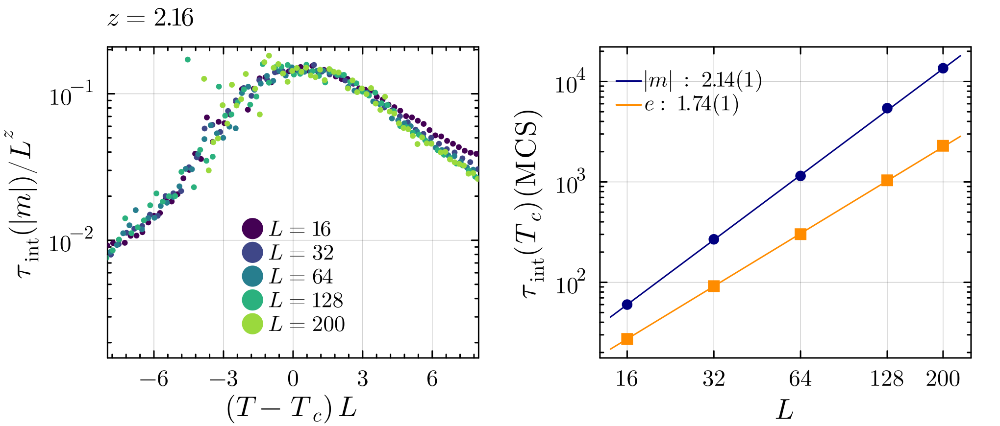

In [39]:
let
    zsum = leer(ANA, "dynamic_exponent_z_summary.csv")
    tau  = leer(ANA, "dynamic_exponent_z_tau_at_Tc.csv")
    z_col = zsum.z[occursin.("collapse", zsum.method)][1]

    p1 = plot(xlabel = L"(T - T_c)\, L", ylabel = L"\tau_\mathrm{int}(|m|) / L^{z}", yscale = :log10,
              xlims = (-8, 8), legend = :bottom, title = latexstring(@sprintf("z = %.2f", z_col)))
    for L in Ls
        d = leer(DATA, "decorrelation_L$(L)_nT96.csv")
        scatter!(p1, (d.T .- Tc_ex) .* L, d.tau_int_mag ./ L^z_col, color = colL[L], ms = 2.2, label = labL(L))
    end

    p2 = plot(xlabel = L"L", ylabel = L"\tau_\mathrm{int}(T_c) \, \mathrm{(MCS)}", xscale = :log10, yscale = :log10,
              xticks = (Ls, string.(Ls)), legend = :topleft)
    Lfino = range(14, 230, length = 50)
    for (obs, nombre, mk, c) in [("abs_m", "|m|", :circle, :navy), ("energy", "e", :square, :darkorange)]
        s = sort!(tau[tau.observable .== obs, :], :L)
        Lf = Float64.(s.L)
        f = linear_fit(log.(Lf), log.(s.tau_int_Tc); sigma = s.rel_err)
        scatter!(p2, Lf, s.tau_int_Tc, yerror = s.tau_int_Tc .* s.rel_err, marker = mk, color = c, ms = 4, label = "")
        plot!(p2, Lfino, exp(f.intercept) .* Lfino .^ f.slope, color = c, lw = 1,
              label = latexstring(@sprintf("%s: \\; %.2f(%d)", nombre, f.slope, round(Int, 100 * f.slope_err))))
        @printf("%-6s z = %.3f +/- %.3f\n", obs, f.slope, f.slope_err)
    end

    fig = plot(p1, p2, layout = (1, 2), size = (ANCHO, 290))
    guardar(fig, "dynamic_exponent_z")
end

## Control

In [ ]:
for f in sort(filter(f -> endswith(f, ".pdf"), readdir(OUT)))
    println(f)
end